# Revenue Regression Modeling — v1.0

## Objective
Predict `total_revenue_usd_m` (team-level total revenue = sponsorship revenue + prize money) for each constructor-season, using the cleaned/merged dataset from `Data_Selection_Preprocessing.ipynb`.

## Target change from the earlier notebooks
The preprocessing and feature-engineering notebooks modeled `prize_money_usd_m` as the target, and explicitly excluded `total_revenue_usd_m` from all features because it is arithmetically derived (`sponsorship_revenue_usd_m + prize_money_usd_m`).

Here the target flips to **`total_revenue_usd_m`**. That flip changes what counts as leakage:
- `sponsorship_revenue_usd_m` and `prize_money_usd_m` are now the two components that *sum to* the target — keeping either as a feature would let the model reconstruct the target almost perfectly (leakage), so **both are dropped from the feature set**.
- Everything else from the validated feature set (operating budget, cost cap fields, season, team dummies, `total_revenue_usd_m_group`, and the engineered ratios) is kept.

## Models compared
- Linear Regression (baseline)
- Ridge Regression (L2-regularized)
- Lasso Regression (L1-regularized, does feature selection)
- Random Forest Regressor (non-linear baseline)

Evaluated with 5-fold cross-validation on the training set, then a final check on the held-out test set, using R², MAE, and RMSE.

## 1. Load data

Reloading from the same source files your preprocessing notebook used, so this notebook is self-contained and doesn't depend on re-running the others.

In [1]:
import os
import numpy as np
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("sergionefedov/formula-1-racing-industry-2010-2026")
constructor_finances_data = pd.read_csv(os.path.join(path, "constructor_finances.csv"))
f1_business_data = pd.read_csv(os.path.join(path, "f1_business.csv"))

print(constructor_finances_data.shape, f1_business_data.shape)

100%|██████████| 14.6k/14.6k [00:00<00:00, 825kB/s]

Extracting files...
(164, 10) (17, 10)


## 2. Rebuild the cleaned/merged dataframe

Same steps as `Data_Selection_Preprocessing.ipynb`: fill the structural `cost_cap_limit_usd_m` missing values with 0, left-join on `season`, encode flags, one-hot encode `team_name`.

In [8]:
cf = constructor_finances_data.copy()
cf["cost_cap_limit_usd_m"] = cf["cost_cap_limit_usd_m"].fillna(0)

merged = cf.merge(f1_business_data, on="season", how="left", suffixes=("", "_group"))

merged["in_cost_cap_era"] = merged["in_cost_cap_era"].astype(int)
merged["is_constructors_champion"] = merged["is_constructors_champion"].astype(int)

merged = pd.get_dummies(merged, columns=["team_name"], prefix="team", drop_first=True)

print(merged.shape)
assert merged.isna().sum().sum() == 0

(164, 27)


## 3. Engineered features

Reusing the same ratio features from `Feature_Engineering_and_Feature_Selection.ipynb`. These are built from `operating_budget_usd_m` and `cost_cap_limit_usd_m` only — not from the target's two components — so they don't reintroduce leakage.

In [9]:
merged["budget_margin"] = merged["cost_cap_limit_usd_m"] - merged["operating_budget_usd_m"]
merged["cost_cap_utilization"] = merged["operating_budget_usd_m"] / merged["cost_cap_limit_usd_m"].replace(0, np.nan)
merged["cost_cap_utilization"] = merged["cost_cap_utilization"].fillna(0)  # pre-cost-cap-era rows

merged[["budget_margin", "cost_cap_utilization"]].describe()

,budget_margin,cost_cap_utilization
count,164.000000,164.000000
mean,-182.884756,0.679461
std,128.414880,1.014140
min,-502.900000,0.000000
25%,-292.200000,0.000000
50%,-137.750000,0.000000
75%,-94.400000,1.266890
max,15.300000,3.329630


## 4. Define target and feature set

**Target:** `total_revenue_usd_m`

**Dropped as leakage:** `sponsorship_revenue_usd_m`, `prize_money_usd_m` — these sum to the target by construction.

**Also dropped:** `is_constructors_champion` (kept for the classification task in the other notebook, not relevant here and downstream of revenue anyway).

In [10]:
target_col = "total_revenue_usd_m"
leak_cols = ["sponsorship_revenue_usd_m", "prize_money_usd_m"]
drop_cols = leak_cols + [target_col, "is_constructors_champion","country_iso3"]

feature_cols = [c for c in merged.columns if c not in drop_cols]

X = merged[feature_cols].copy()
y = merged[target_col].copy()

# safety check: confirm no leakage column slipped into X
assert not any(c in X.columns for c in leak_cols + [target_col])

print("Features:", X.shape[1])
print(X.columns.tolist())

Features: 24
['season', 'operating_budget_usd_m', 'in_cost_cap_era', 'cost_cap_limit_usd_m', 'total_revenue_usd_m_group', 'race_promotion_fees_usd_m', 'broadcast_media_usd_m', 'sponsorship_usd_m', 'other_revenue_usd_m', 'is_liberty_media_era', 'drive_to_survive_viewers_m_est', 'us_avg_race_viewers_m', 'global_avg_race_viewers_m', 'team_Aston Martin', 'team_Ferrari', 'team_Haas', 'team_McLaren', 'team_Mercedes', 'team_RB (AlphaTauri)', 'team_Red Bull Racing', 'team_Stake (Sauber)', 'team_Williams', 'budget_margin', 'cost_cap_utilization']


## 5. Train/test split

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (131, 24)  Test: (33, 24)


## 6. Sanity check: correlation of the two dropped components with revenue

Confirms *why* they were dropped — not a modeling step, just documentation of the leakage risk.

In [12]:
check = merged[["sponsorship_revenue_usd_m", "prize_money_usd_m", "total_revenue_usd_m"]].corr()["total_revenue_usd_m"]
print(check)

sponsorship_revenue_usd_m    0.973505
prize_money_usd_m            0.928867
total_revenue_usd_m          1.000000
Name: total_revenue_usd_m, dtype: float64


## 7. Model training and comparison

Four regressors, 5-fold cross-validation on the training set. Ridge/Lasso and the tree model don't strictly need scaling, but linear-model coefficients are easier to compare on a common scale, so a `StandardScaler` is included in each pipeline for the linear models. Random Forest is left unscaled (tree splits are scale-invariant).

In [13]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, random_state=42, max_iter=10000))
    ]),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
}

scoring = ["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]

cv_results = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=5, scoring=scoring)
    cv_results.append({
        "Model": name,
        "R2 (mean)": scores["test_r2"].mean(),
        "R2 (std)": scores["test_r2"].std(),
        "MAE (mean)": -scores["test_neg_mean_absolute_error"].mean(),
        "RMSE (mean)": -scores["test_neg_root_mean_squared_error"].mean(),
    })

cv_df = pd.DataFrame(cv_results).sort_values("R2 (mean)", ascending=False)
cv_df

,Model,R2 (mean),R2 (std),MAE (mean),RMSE (mean)
2,Lasso,0.937422,0.018854,23.395012,33.319458
1,Ridge,0.935641,0.016178,24.979244,33.848704
3,Random Forest,0.935063,0.022368,23.781342,33.510962
0,Linear Regression,0.922862,0.018850,28.036579,37.085675


## 8. Fit on full training set, evaluate on held-out test set

In [14]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

test_results = []
fitted_models = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    preds = pipe.predict(X_test)
    test_results.append({
        "Model": name,
        "Test R2": r2_score(y_test, preds),
        "Test MAE": mean_absolute_error(y_test, preds),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, preds)),
    })

test_df = pd.DataFrame(test_results).sort_values("Test R2", ascending=False)
test_df

,Model,Test R2,Test MAE,Test RMSE
2,Lasso,0.901920,33.148164,43.130152
1,Ridge,0.897380,34.248342,44.117187
0,Linear Regression,0.894557,34.693841,44.719787
3,Random Forest,0.849491,32.328616,53.428490


## 9. Coefficients / feature importance of the best model(s)

Lasso's coefficients show which features it kept (zeroed-out coefficients mean it dropped that feature entirely) — useful for cross-checking against the feature-selection notebook's rankings. Random Forest importances are shown for comparison.

In [15]:
lasso_model = fitted_models["Lasso"].named_steps["model"]
lasso_coefs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso_model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

print("Lasso coefficients (non-zero = kept):")
print(lasso_coefs[lasso_coefs["Coefficient"] != 0])

rf_model = fitted_models["Random Forest"]
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nRandom Forest feature importance (top 10):")
print(rf_importance.head(10))

Lasso coefficients (non-zero = kept):
                      Feature  Coefficient
1      operating_budget_usd_m    48.515183
22              budget_margin   -35.399506
19       team_Red Bull Racing    28.926360
14               team_Ferrari    24.752520
5   race_promotion_fees_usd_m    21.248397
0                      season    20.653923
23       cost_cap_utilization    19.827415
11      us_avg_race_viewers_m    11.470921
15                  team_Haas   -10.511599
20        team_Stake (Sauber)   -10.013782
21              team_Williams    -4.541554
9        is_liberty_media_era    -2.330247
17              team_Mercedes    -0.466851

Random Forest feature importance (top 10):
                      Feature  Importance
1      operating_budget_usd_m    0.823160
23       cost_cap_utilization    0.070749
0                      season    0.018765
16               team_McLaren    0.015725
22              budget_margin    0.013697
19       team_Red Bull Racing    0.008400
6       broadcast_medi

## 10. Predicted vs actual plot (best model)

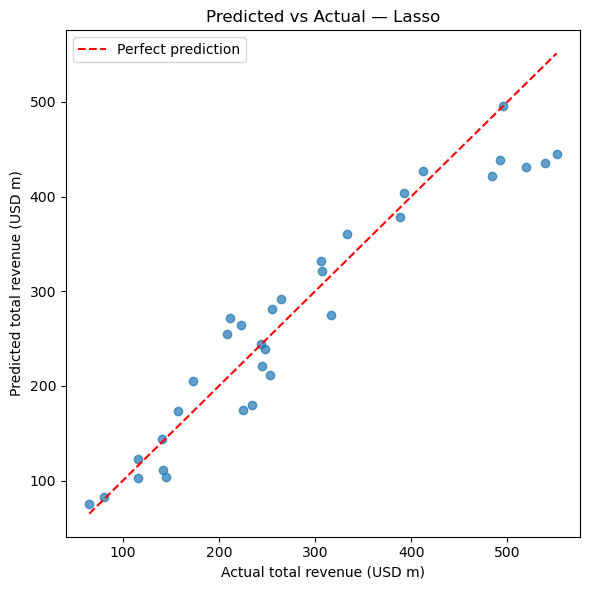

In [16]:
import matplotlib.pyplot as plt

best_name = test_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
preds = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds, alpha=0.7)
lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
plt.plot(lims, lims, 'r--', label="Perfect prediction")
plt.xlabel("Actual total revenue (USD m)")
plt.ylabel("Predicted total revenue (USD m)")
plt.title(f"Predicted vs Actual — {best_name}")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Summary

- Target:*total_revenue_usd_m (team-level total revenue)
- **Leakage handling: sponsorship_revenue_usd_m and prize_money_usd_m excluded from features since they sum to the target by construction; this is a stricter cut than the earlier prize-money notebooks needed
- Models compared:Linear Regression, Ridge, Lasso, and Random Forest. Lasso performed best during cross-validation (Mean $R^2$: 0.9374), closely followed by Ridge (0.9356) and Random Forest (0.9350), while Linear Regression performed worst (0.9228).
- Best model: Lasso Regression, selected by test $R^2$. It achieved a 0.9019 $R^2$ score on the held-out test data, with a Mean Absolute Error (MAE) of 33.15 million USD and a Root Mean Squared Error (RMSE) of 43.13 million USD